# 01 · Data Exploration

**Project:** Real Estate Spatial & Price Clustering  
**Dataset:** California Housing Prices — `data/housing.csv` (20,640 census block groups, 1990)

This notebook inspects the raw data *before* changing anything: dimensions, data
types, missing values, distributions, geography and outliers. The observations
here motivate every preprocessing decision in `02_data_preprocessing.ipynb`.

## 1. Load the dataset

In [2]:
%matplotlib inline

import os
import sys
from pathlib import Path

# Avoid a noisy joblib CPU-detection warning on Windows.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root (the folder that contains src/) so the notebooks run
# whether Jupyter was started from notebooks/ or from the project root.
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import preprocessing as pp
import clustering as cl
import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

print("Project root:", ROOT)
print("Dataset:", pp.DATA_PATH)

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
raw = pp.load_data()

print(f"Rows: {raw.shape[0]:,}")
print(f"Columns: {raw.shape[1]}")
raw.head()

Rows: 20,640
Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 2. Structure and data types

Each row is a census **block group** (roughly 600–3,000 people), not a single
house. This matters: `total_rooms`, `population` and `households` are district
totals, which is why we later build per-household ratios.

In [ ]:
structure = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "unique_values": raw.nunique(),
})
structure

,dtype,non_null,missing,missing_pct,unique_values
longitude,float64,20640,0,0.0,844
latitude,float64,20640,0,0.0,862
housing_median_age,float64,20640,0,0.0,52
total_rooms,float64,20640,0,0.0,5926
total_bedrooms,float64,20433,207,1.0,1923
population,float64,20640,0,0.0,3888
households,float64,20640,0,0.0,1815
median_income,float64,20640,0,0.0,12928
median_house_value,float64,20640,0,0.0,3842
ocean_proximity,str,20640,0,0.0,5


In [ ]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


## 3. Missing values and duplicates

Only `total_bedrooms` has missing values. The number is small enough that
imputation is preferable to dropping rows.

In [ ]:
missing = raw.isna().sum()
missing = missing[missing > 0]
print(f"Rows with at least one missing value: {raw.isna().any(axis=1).sum():,}")
print(f"Duplicated rows: {raw.duplicated().sum():,}")
print(f"Missing share of total_bedrooms: {raw['total_bedrooms'].isna().mean() * 100:.2f}%")
missing.to_frame("missing_count")

Rows with at least one missing value: 207
Duplicated rows: 0
Missing share of total_bedrooms: 1.00%


,missing_count
total_bedrooms,207


## 4. Ocean proximity

`ocean_proximity` is the only categorical column. It is descriptive, not used
as a clustering input (the coordinates already encode location), but it is
useful for interpreting clusters.

In [ ]:
ocean_counts = raw["ocean_proximity"].value_counts()
share = (ocean_counts / len(raw) * 100).round(2)
pd.DataFrame({"block_groups": ocean_counts, "share_pct": share})

,block_groups,share_pct
ocean_proximity,,
<1H OCEAN,9136,44.26
INLAND,6551,31.74
NEAR OCEAN,2658,12.88
NEAR BAY,2290,11.09
ISLAND,5,0.02


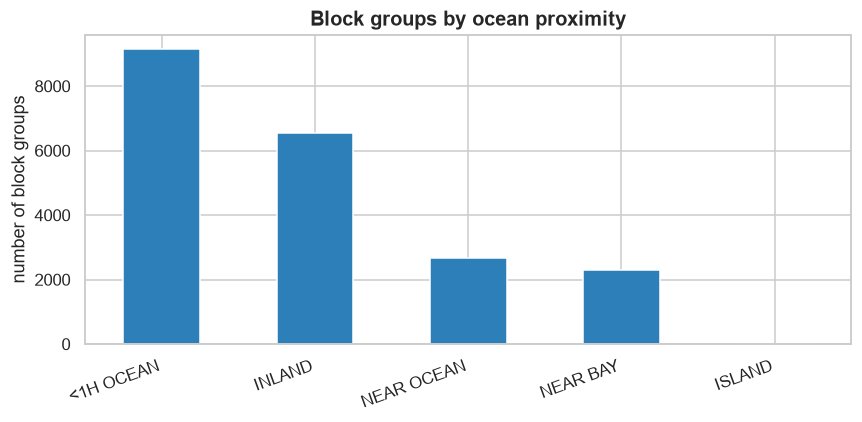

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ocean_counts.plot(kind="bar", color="#2c7fb8", ax=ax)
ax.set_title("Block groups by ocean proximity")
ax.set_ylabel("number of block groups")
ax.set_xlabel("")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.show()

## 5. House price distribution

The target is heavily right-skewed and has a hard ceiling at **\$500,001**:
prices were top-coded in the original 1990 census extract. Those 4.68% of rows
are real records, not errors, so they are kept — removing them would delete many
of the most expensive coastal areas we want to study.

min:    $14,999
median: $179,700
mean:   $206,856
max:    $500,001
skewness: 0.98
rows at the $500,001 cap: 965 (4.68%)


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\price_distribution.png


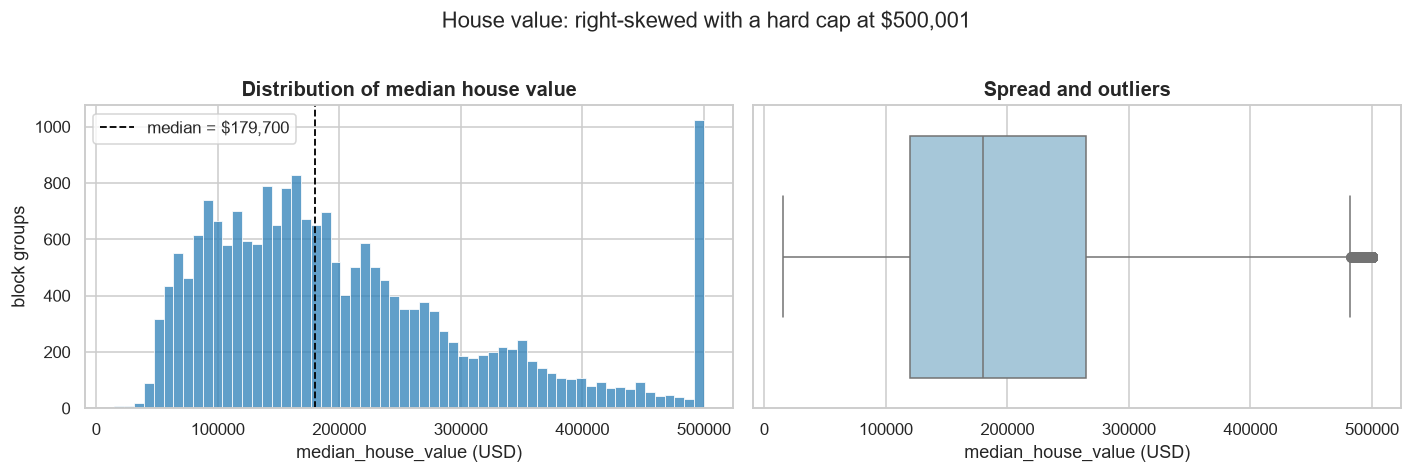

In [ ]:
price = raw["median_house_value"]
capped = int((price >= 500001).sum())

print(f"min:    ${price.min():,.0f}")
print(f"median: ${price.median():,.0f}")
print(f"mean:   ${price.mean():,.0f}")
print(f"max:    ${price.max():,.0f}")
print(f"skewness: {price.skew():.2f}")
print(f"rows at the $500,001 cap: {capped:,} ({capped / len(raw) * 100:.2f}%)")

fig, path = viz.plot_price_distribution(raw)
print("saved:", path)
plt.show()

## 6. Feature distributions

Room counts, population and households have long right tails: a small number of
very large block groups sit far above the rest. `housing_median_age` is bounded
(1–52) and much better behaved.

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\feature_distributions.png


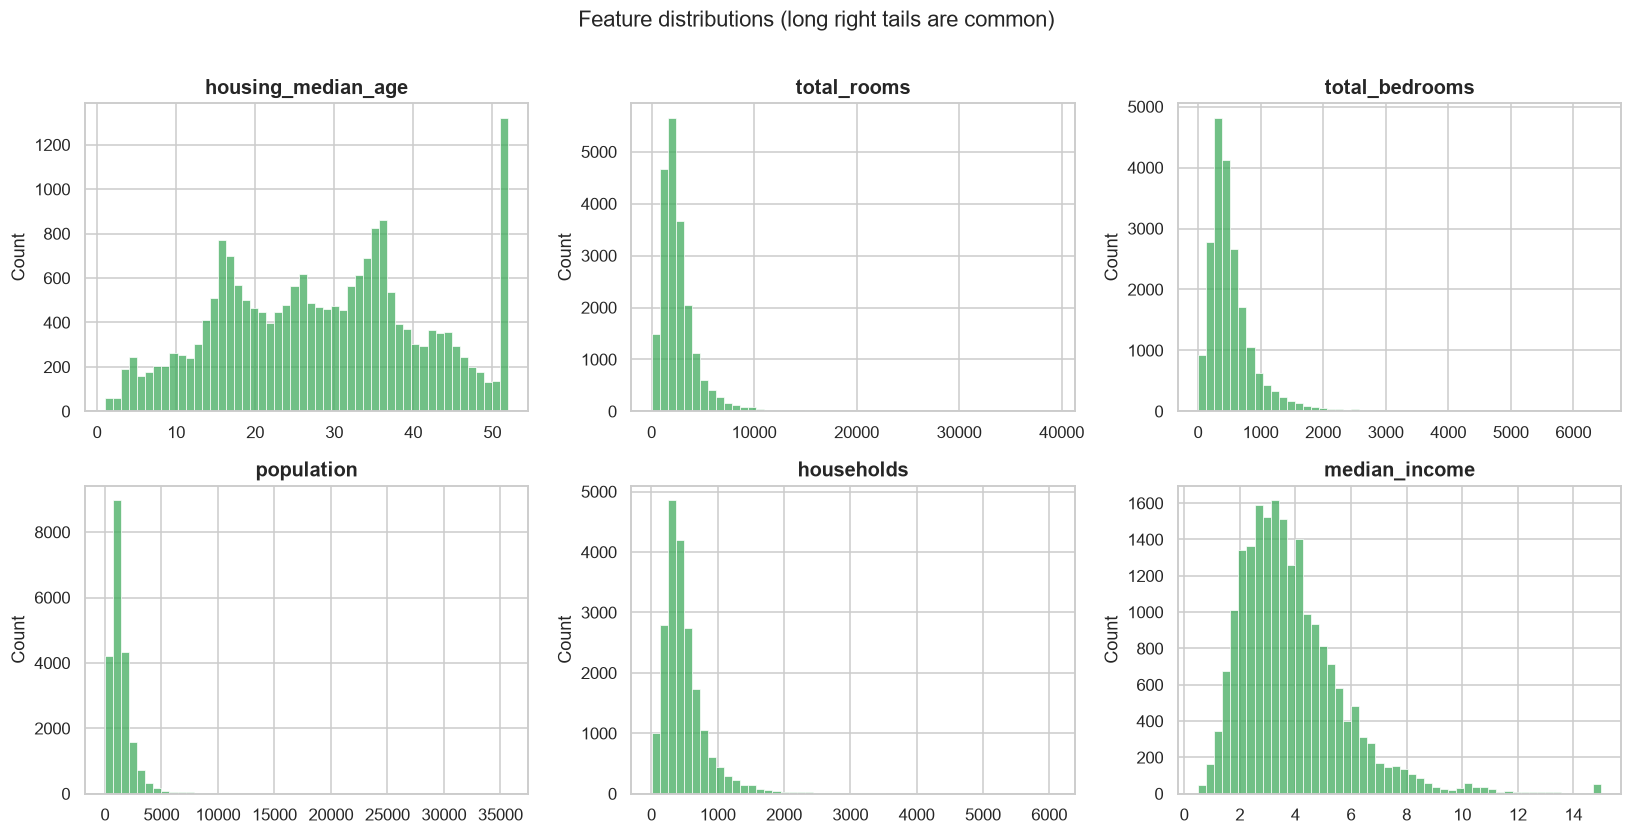

In [ ]:
fig, path = viz.plot_feature_distributions(
    raw,
    columns=["housing_median_age", "total_rooms", "total_bedrooms",
             "population", "households", "median_income"],
)
print("saved:", path)
plt.show()

## 7. Geography and prices

Plotting longitude against latitude reproduces the map of California. Expensive
block groups concentrate along the coast (Bay Area, Los Angeles, San Diego,
Santa Barbara), while the Central Valley and inland desert are cheaper. This
spatial pattern is exactly what the clustering in notebooks 03–05 explores.

      longitude  latitude
min     -124.35    32.540
max     -114.31    41.950
mean    -119.57    35.632


saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\housing_geography.png


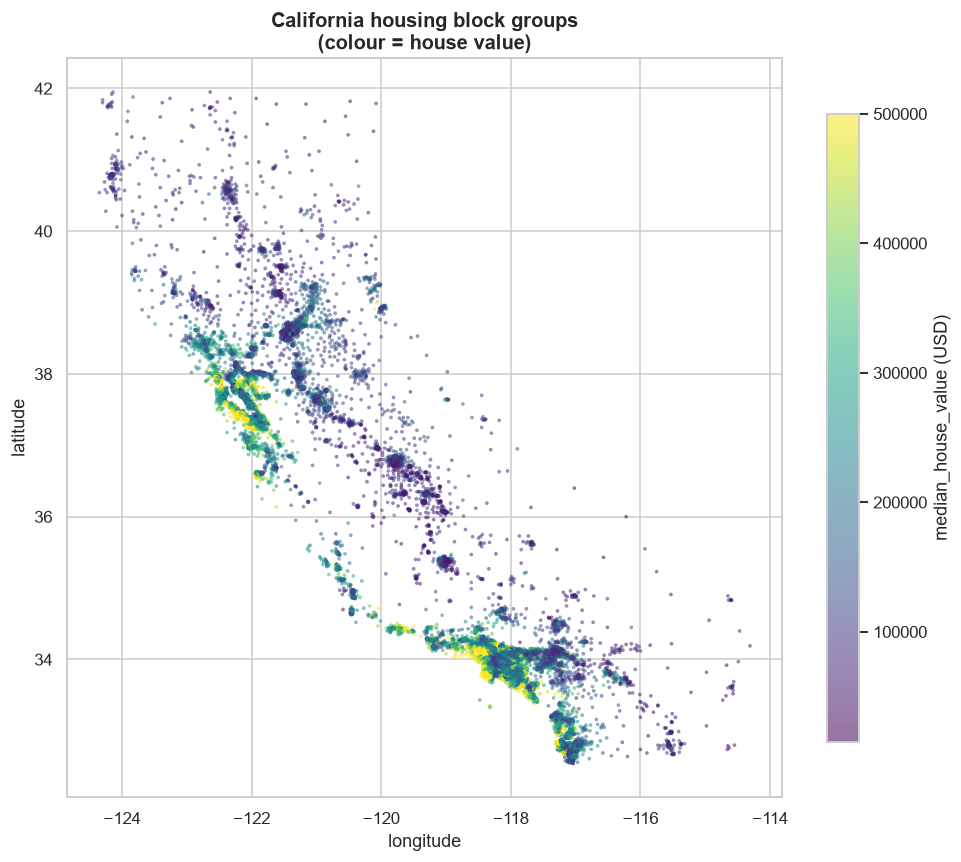

interactive map: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\maps\housing_geography.html


interactive price chart: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\price_distribution_interactive.html


In [ ]:
print(raw[["longitude", "latitude"]].agg(["min", "max", "mean"]).round(3))

fig, path = viz.plot_geography(raw)
print("saved:", path)
plt.show()

map_path = viz.build_geography_map(raw)
print("interactive map:", map_path)

price_html = viz.save_plotly_price_chart(raw)
print("interactive price chart:", price_html)

## 8. Correlations with house value

`median_income` is by far the strongest linear correlate of house value
(**r ≈ 0.69**). Geographic coordinates have weak *linear* correlations
(r ≈ −0.14 for latitude), which is expected: the relationship is spatial and
non-linear, so distance-based clustering is the right tool rather than a simple
correlation.

saved: D:\proj\Real-Estate-Spatial-Price-Clustering\real-estate-clustering\outputs\visualizations\correlation_heatmap.png


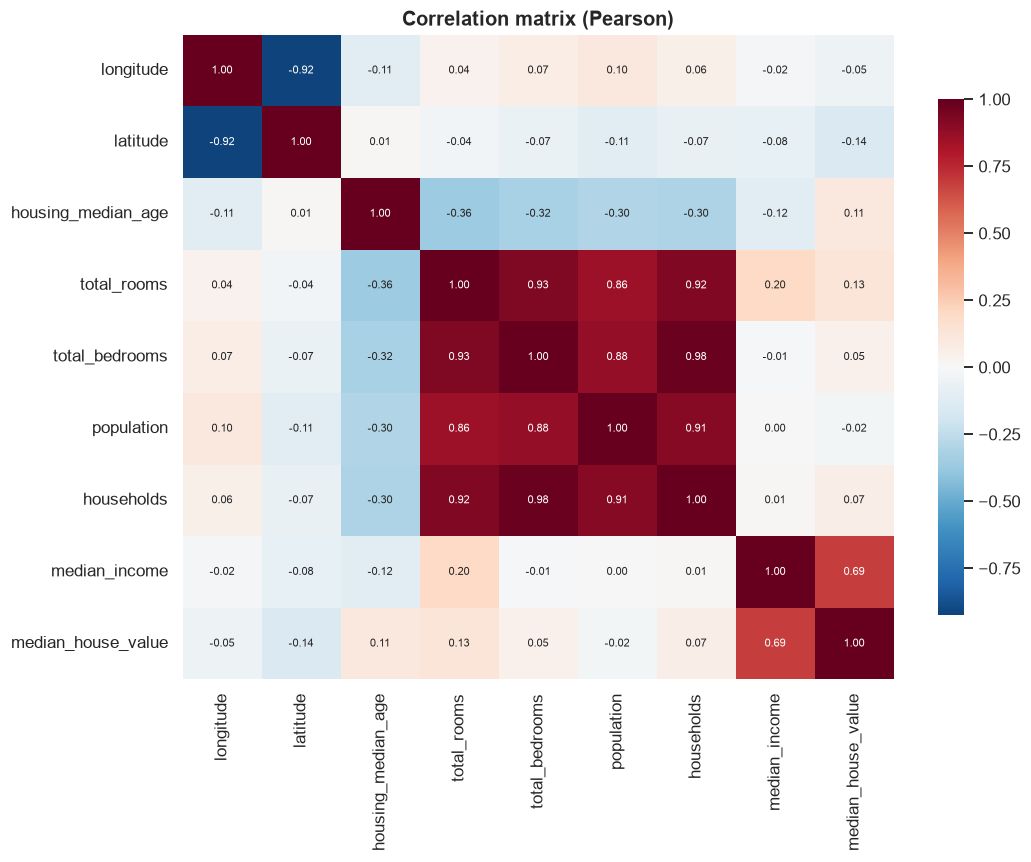

median_income         0.688
latitude             -0.144
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
longitude            -0.046
population           -0.025
Name: median_house_value, dtype: float64


In [ ]:
corr_cols = [
    "longitude", "latitude", "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households", "median_income",
    "median_house_value",
]
fig, path = viz.plot_correlation_heatmap(raw, columns=corr_cols)
print("saved:", path)
plt.show()

print(raw[corr_cols].corr()["median_house_value"].drop("median_house_value")
      .sort_values(key=abs, ascending=False).round(3))

## 9. Outliers in the raw counts

IQR fences flag many rows, but these are mostly genuine large districts. The
right fix is not to delete them: it is to (a) add per-household ratios so that
district size stops driving the signal, and (b) standardise features before
distance-based clustering.

In [ ]:
outlier_rows = []
for col in ["total_rooms", "total_bedrooms", "population", "households", "median_income"]:
    q1, q3 = raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    outlier_rows.append({
        "column": col,
        "p99": raw[col].quantile(0.99),
        "max": raw[col].max(),
        "IQR_upper_fence": upper,
        "values_above_fence": int((raw[col] > upper).sum()),
    })

pd.DataFrame(outlier_rows).round(2)

,column,p99,max,IQR_upper_fence,values_above_fence
0,total_rooms,11212.11,39320.0,5698.38,1287
1,total_bedrooms,2221.36,6445.0,1173.50,1271
2,population,5805.83,35682.0,3132.00,1196
3,households,1982.66,6082.0,1092.50,1220
4,median_income,10.60,15.0,8.01,681


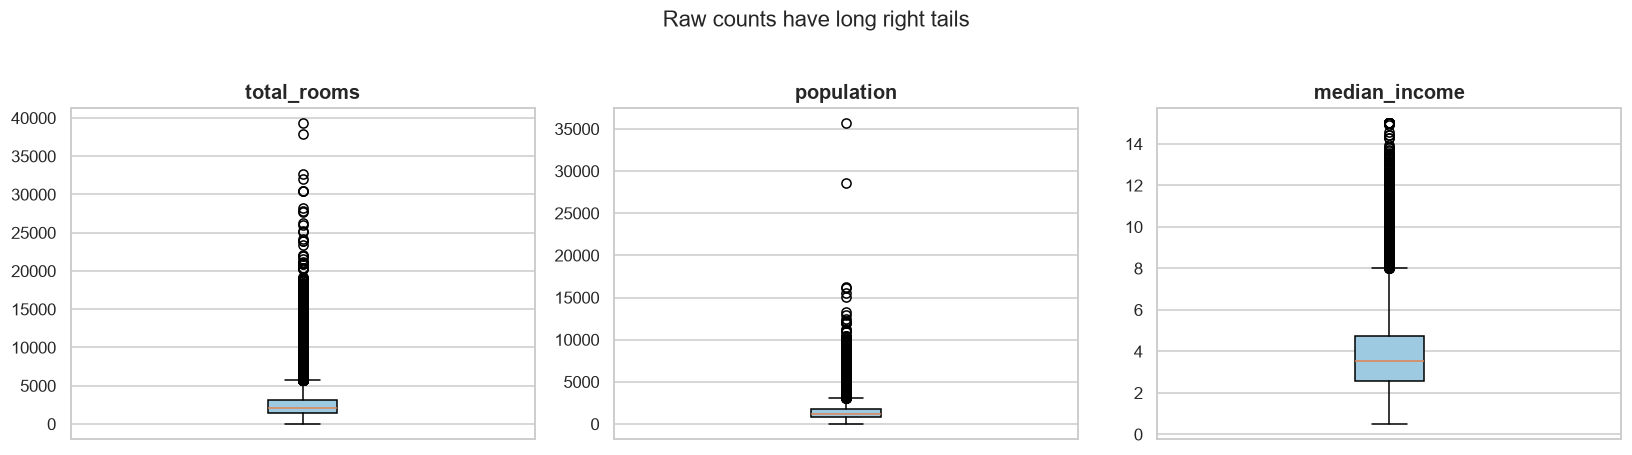

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["total_rooms", "population", "median_income"]):
    ax.boxplot(raw[col], patch_artist=True,
               boxprops=dict(facecolor="#9ecae1"))
    ax.set_title(col)
    ax.set_xticks([])
fig.suptitle("Raw counts have long right tails", y=1.03)
plt.show()

## 10. Engineered ratios preview

Ratios remove most of the district-size effect, but they expose a handful of
non-residential records: the maximum of **1,243 people per household** is not a
real housing situation. Notebook 02 winsorises these ratio features.

In [ ]:
preview = pp.add_features(raw)
preview[["rooms_per_household", "bedrooms_per_room", "population_per_household"]] \
    .describe(percentiles=[0.01, 0.5, 0.99]).T.round(3)

,count,mean,std,min,1%,50%,99%,max
rooms_per_household,20640.0,5.429,2.474,0.846,2.581,5.229,10.357,141.909
bedrooms_per_room,20433.0,0.213,0.058,0.100,0.124,0.203,0.407,1.000
population_per_household,20640.0,3.071,10.386,0.692,1.537,2.818,5.395,1243.333


## Key findings

- **20,640 rows × 10 columns**; one row = one census block group.
- **207 missing values**, all in `total_bedrooms` (1.00%). No duplicate rows.
- House value is right-skewed (skew ≈ 0.98), median **\$179,700**, and **965 rows
  (4.68%)** are capped at \$500,001.
- `median_income` correlates **0.69** with price; raw counts correlate only weakly.
- The coastline is clearly visible, with expensive block groups concentrated in
  the Bay Area, Los Angeles, San Diego and Santa Barbara.
- Extreme raw counts and impossible ratios exist, so preprocessing must handle
  outliers and scaling.